In [27]:
import numpy as np
import pandas as pd
import math
from uncertainties import unumpy as unp
from uncertainties import ufloat as uf
import numpy as np
import uncertainties.umath as umath
import matplotlib.pyplot as plt
from scipy import stats

def plot_cycle(df, xlabel=None, ylabel=None, title=None, show=True):
    """Plot a closed cycle (2nd column = X, 3rd column = Y) and shade its interior.

    Returns
    -------
    integral : closed-loop integral of y dx (float, or ufloat if the data are ufloats)
    d_first  : last minus first entry of the first column
    (x_min, x_max), (y_min, y_max) : tuple of floats
    """
    x = df.iloc[:, 1].values
    y = df.iloc[:, 2].values

    # Close the loop explicitly by appending the first point at the end
    x_closed = np.append(x, x[0])
    y_closed = np.append(y, y[0])

    # Closed-loop integral of y dx (trapezoid rule, including the closing segment)
    integral = np.sum((y_closed[1:] + y_closed[:-1]) / 2 * (x_closed[1:] - x_closed[:-1]))

    d_first = df.iloc[-1, 0] - df.iloc[0, 0]

    xn = np.asarray(unp.nominal_values(x_closed), dtype=float)
    yn = np.asarray(unp.nominal_values(y_closed), dtype=float)

    fig, ax = plt.subplots()
    ax.fill(xn, yn, alpha=0.3, color="tab:blue")
    ax.plot(xn, yn, "-", color="tab:blue")
    ax.scatter(xn, yn, color="tab:red", zorder=3)

    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if title:  ax.set_title(title)

    if show: plt.show()

    return integral, d_first, (xn.min(), xn.max()), (yn.min(), yn.max())


In [20]:
info_df = pd.read_csv("info.csv")
print(info_df)

eff_arr = []

def get_efficiency(area_prad, x_range, run):
    rotations_in_30s = info_df[info_df["Run"]==run]["rotations_in_30s"].item() 
    rot_per_sec = rotations_in_30s/30

    current = info_df[info_df["Run"]==run]["Current_A"].item()
    voltage = info_df[info_df["Run"]==run]["V"].item()
    Power = current*voltage
    
    dV_per_rad = 150e-6/(x_range[1]-x_range[0])
    energy_per_cycle = dV_per_rad*area_Prad*1000


    energy_per_second = energy_per_cycle*rot_per_sec

    return energy_per_second/Power

   Run  Current_A      V  rotations_in_30s
0    1       9.69  10.05                59
1    2      10.48  10.82                76
2    3      11.04  11.40                84
3    4      11.64  11.95                97
4    5      12.34  12.63               111


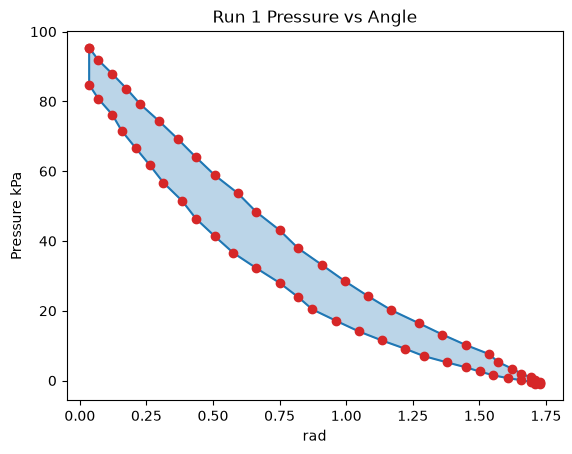

0.03549700508955863


In [34]:
run=1

run_csv = "run_"+str(run)+".csv"

run1_df = pd.read_csv(run_csv)
#print(run1_df.keys())

area_Prad, d_time, x_range, y_range = plot_cycle(run1_df, "rad", "Pressure kPa", f"Run {run} Pressure vs Angle")


eff = get_efficiency(area_Prad, x_range, 1)

print(eff)

eff_arr.append(eff)

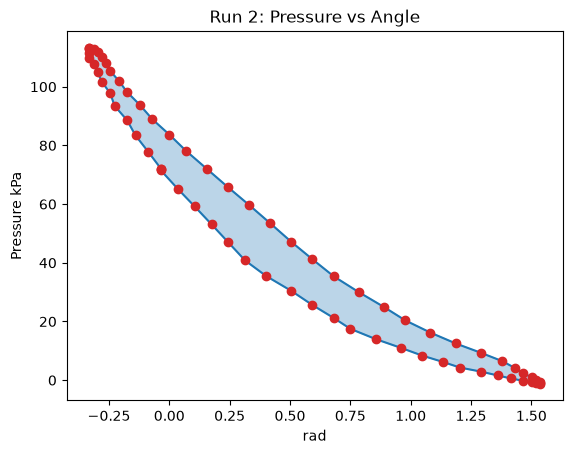

0.0366855422087174


In [33]:
run=2

run_csv = "run_"+str(run)+".csv"

run1_df = pd.read_csv(run_csv)
#print(run1_df.keys())

area_Prad, d_time, x_range, y_range = plot_cycle(run1_df, "rad", "Pressure kPa", f"Run {run}: Pressure vs Angle")


eff = get_efficiency(area_Prad, x_range, 1)

print(eff)

eff_arr.append(eff)

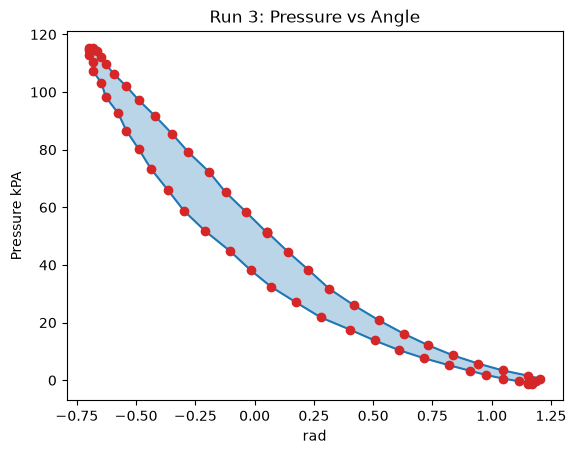

0.03501348133728953


In [32]:
run=3

run_csv = "run_"+str(run)+".csv"

run1_df = pd.read_csv(run_csv)
#print(run1_df.keys())

area_Prad, d_time, x_range, y_range = plot_cycle(run1_df, "rad", "Pressure kPA", f"Run {run}: Pressure vs Angle")


eff = get_efficiency(area_Prad, x_range, 1)

print(eff)

eff_arr.append(eff)

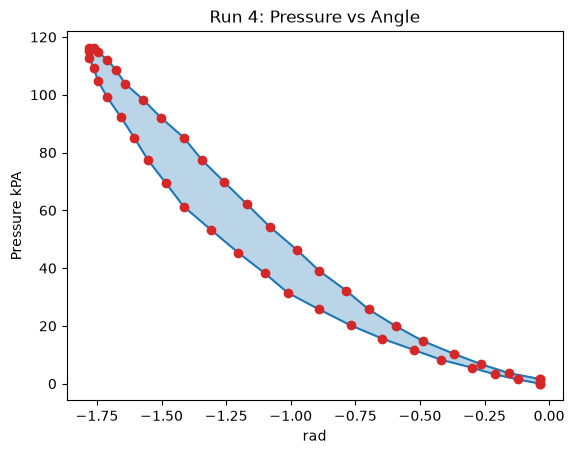

0.03549119925049407


In [35]:
run=4

run_csv = "run_"+str(run)+".csv"

run1_df = pd.read_csv(run_csv)
#print(run1_df.keys())

area_Prad, d_time, x_range, y_range = plot_cycle(run1_df, "rad", "Pressure kPA", f"Run {run}: Pressure vs Angle")


eff = get_efficiency(area_Prad, x_range, 1)

print(eff)

eff_arr.append(eff)

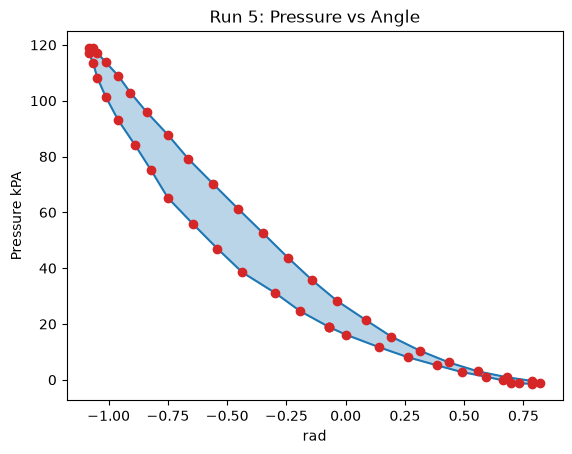

0.034490612754728193


In [42]:
run=5

run_csv = "run_"+str(run)+".csv"

run1_df = pd.read_csv(run_csv)
#print(run1_df.keys())

area_Prad, d_time, x_range, y_range = plot_cycle(run1_df, "rad", "Pressure kPA", f"Run {run}: Pressure vs Angle")

eff = get_efficiency(area_Prad, x_range, 1)

print(eff)

eff_arr.append(eff)

In [41]:
final_eff = uf(np.mean(eff_arr), stats.sem(eff_arr))

print(final_eff)

0.03554+/-0.00022
